In [2]:
'''import numpy as np
from skimage.io import imread
from skimage.filters import frangi
import matplotlib.pyplot as plt
from skimage.morphology import skeletonize, remove_small_objects
from scipy.ndimage import distance_transform_edt
from Skel2Graph3D import skel2graph3d
from Graph2Skel3D import graph2skel3d
import scipy.io as sio
import os
import time'''
from skeletonize_testing import skeletonize_main
from Skel2Graph3D import skel2graph3d
from skimage.morphology import skeletonize, remove_small_objects
import matplotlib.pyplot as plt
import numpy as np

import scipy.io as sio

In [3]:
# metrics
def iou_skeletons(im1: np.ndarray, im2: np.ndarray) -> float:
    """
    Computes the IoU score between two 2D skeletonized images.
    Both images must be binary (0/1 or bool).

    Returns a float in [0, 1] indicating percentage of pixel overlap.
    """

    # Ensure boolean arrays
    im1 = im1.astype(bool)
    im2 = im2.astype(bool)

    intersection = np.logical_and(im1, im2).sum()
    union = np.logical_or(im1, im2).sum()

    if union == 0:
        return 1.0 if intersection == 0 else 0.0

    return intersection / union

# Summary
- **Test 1**: running both images in their separate pipelines and comparing final answer (what I sent to Mila last week)

Result: images disagree (IoU = 0.46)

- **Test 2:** running the semi-skeletonized image from matlab through the python pipeline to make sure skel2graph3d and graph2skel3d work exactly as the matlab implementation

Result: for some reason, the kernel crashes after attempting to run skel2graph3d. Possibly because the skeleton is a massive connected component that pk_follow_link simply cannot process easily, but I'm not sure

- **Test 3** running the semi-skeletonized image from python through the matlab pipeline to make sure skel2graph3d and graph2skel3d work exactly as the matlab implementation

Result: 

# Test 1: Comparison across pipelines

In [6]:
THR = 1 # hyperparameter (same one used in Matlab pipeline )

# load binary image
data = sio.loadmat("/Users/mutrera/Documents/Uchicago College/Uchicago 2024 - 2025/Summer/Octava/octava/code/Skeletonization/matlab_skels/binarise_python_result.mat")
python_bin_img = data['Y_py']

skel, nodes, links = skeletonize_main(python_bin_img, THR)
py_skel = skel[:, :, 0]

# load matlab skeleton
mat_skel = sio.loadmat('/Users/mutrera/Documents/Uchicago College/Uchicago 2024 - 2025/Summer/Octava/octava/code/Skeletonization/matlab_skels/mat_skel_full.mat')
mat_skel = mat_skel['skel2']

Time for skel2graph: 59.61373019218445
Time for graph2skel: 0.013608932495117188
Time in cleaning loop: 226.48111176490784


agreement: 0.954762
diff pixels: 45238


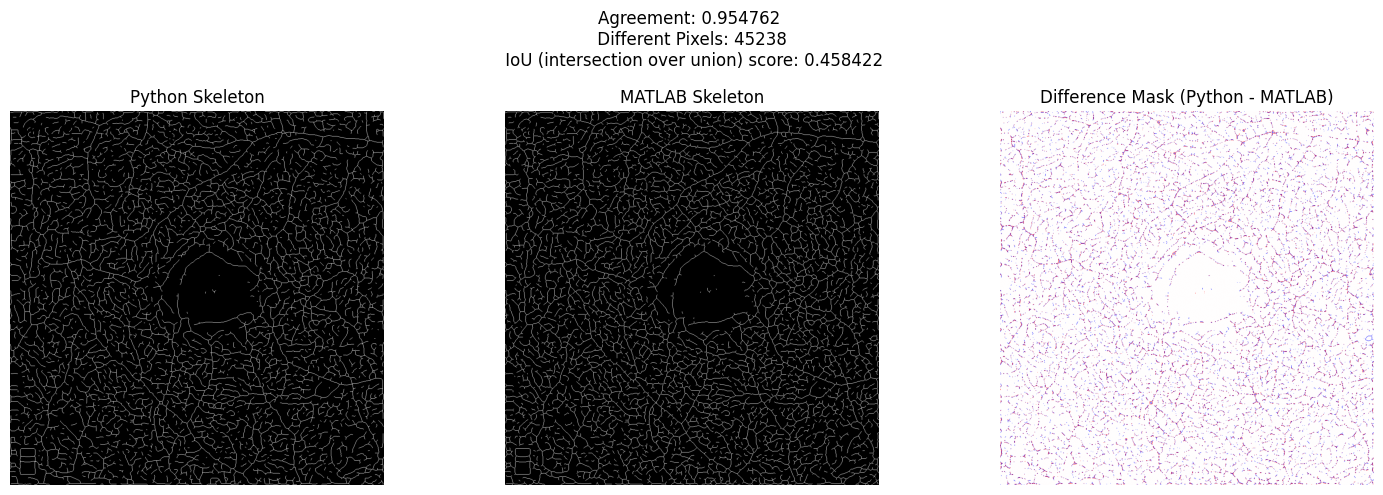

In [7]:
# plotting differences
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

axes[0].imshow(py_skel, cmap='gray')
axes[0].set_title("Python Skeleton")
axes[0].axis('off')

axes[1].imshow(mat_skel, cmap='gray')
axes[1].set_title("MATLAB Skeleton")
axes[1].axis('off')

difference_mask = py_skel.astype(int) - mat_skel.astype(int)
axes[2].imshow(difference_mask, cmap='bwr')  # blue=matlab-only, red=python-only
axes[2].set_title("Difference Mask (Python - MATLAB)")
axes[2].axis('off')

tol = 1e-5
float_close = np.isclose(py_skel, mat_skel, atol=tol)
float_agreement = float_close.mean()
print(f"agreement: {float_agreement:.6f}")
print("diff pixels:", np.sum(~float_close))

plt.suptitle(f"Agreement: {float_agreement:.6f} \n Different Pixels: {np.sum(~float_close)} \n IoU (intersection over union) score: {iou_skeletons(py_skel, mat_skel):.6f}\n")
plt.tight_layout()
plt.show()

# Test 2: Semi-skeleton from Matlab through Python

In [29]:
semi_skel_mat = sio.loadmat('/Users/mutrera/Documents/Uchicago College/Uchicago 2024 - 2025/Summer/Octava/octava/code/Skeletonization/matlab_skels/semi_skel_mat.mat')
semi_skel_mat = semi_skel_mat['semi_skel_mat']
semi_skel_mat = semi_skel_mat.astype(bool)

nodes, links = skel2graph3d(semi_skel_mat, THR)

: 

# Test 3: semi-skeleton from Python through Matlab

In [9]:
mat_skel = sio.loadmat('/Users/mutrera/Documents/Uchicago College/Uchicago 2024 - 2025/Summer/Octava/octava/code/Skeletonization/matlab_skels/mat_bin_skel_w_python_result.mat')
mat_skel = mat_skel['sk2']

agreement: 0.999329
diff pixels: 671


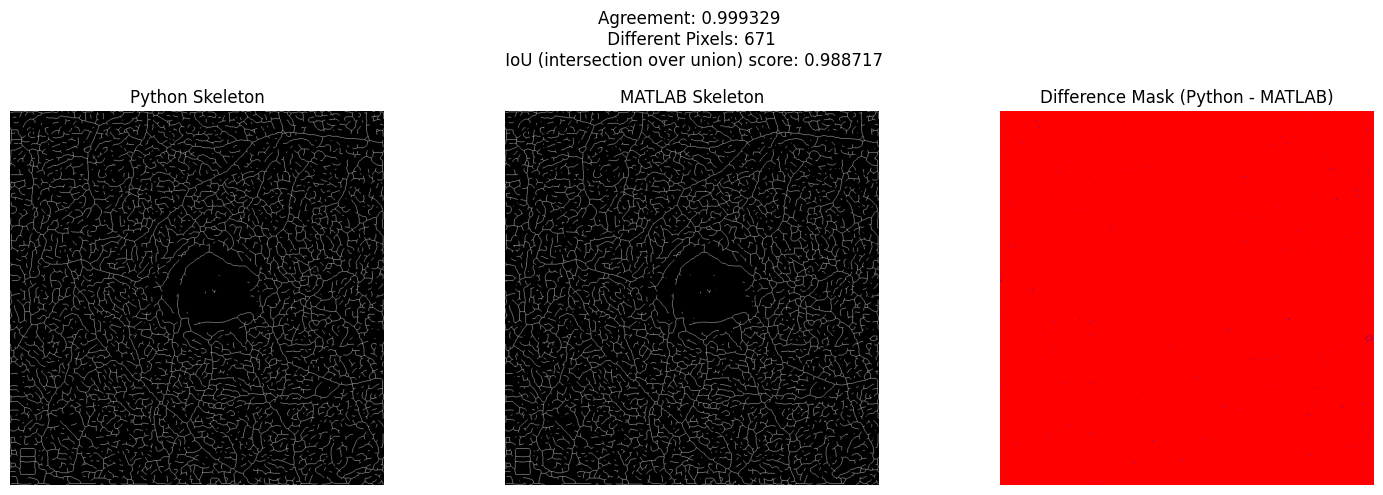

In [10]:
# plotting differences
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

axes[0].imshow(py_skel, cmap='gray')
axes[0].set_title("Python Skeleton")
axes[0].axis('off')

axes[1].imshow(mat_skel, cmap='gray')
axes[1].set_title("MATLAB Skeleton")
axes[1].axis('off')

difference_mask = py_skel.astype(int) - mat_skel.astype(int)
axes[2].imshow(difference_mask, cmap='bwr')  # blue=matlab-only, red=python-only
axes[2].set_title("Difference Mask (Python - MATLAB)")
axes[2].axis('off')

tol = 1e-5
float_close = np.isclose(py_skel, mat_skel, atol=tol)
float_agreement = float_close.mean()
print(f"agreement: {float_agreement:.6f}")
print("diff pixels:", np.sum(~float_close))

plt.suptitle(f"Agreement: {float_agreement:.6f} \n Different Pixels: {np.sum(~float_close)} \n IoU (intersection over union) score: {iou_skeletons(py_skel, mat_skel):.6f}\n")
plt.tight_layout()
plt.show()